# 09 · The single test run

This is the **only** notebook that reads test-split PM2.5 (forecasting test winter 2024/25) and the network test months (Feb–Mar 2026). It runs **once**, after the tag **`pre-test-v2`** (moved forward from 23 November; the rule is unchanged). Nothing chosen earlier changes: models, configurations, thresholds, features, grids and seeds are those frozen at tag **`pre-test-v2`** (`configs/study_config.yaml`, `outputs/results/forecast_selected.json`, `warning_policy.json`, `network_validation.csv`); their SHA-256 hashes are logged in section 1. All logic lives in `src/uaq/test_run.py`, which only calls the frozen functions.

**The run refuses to start** if the working tree is not clean, any frozen file changed since `pre-test-v2` (configs and earlier results byte for byte; model code compared without docstrings), or `outputs/results/test_run_log.json` already exists (no re-runs; the only allowed re-run fixes a bug in evaluation code and is logged with its reason).

## Verdict rules (fixed before any test number is printed)
- **H1** (forecasting): SUPPORTED if the MLP (weather), the neural network selected on validation, has positive MAE skill over persistence on the test smog-season days **and** the 95% interval of MAE(MLP) − MAE(persistence) from a paired 7-day block bootstrap (1,000 resamples, seed 0) lies below 0; otherwise NOT SUPPORTED. The LSTM is reported as secondary.
- **H2** (weather): SUPPORTED if the MLP's test MAE with weather is lower than without, on identical days; all families are reported.
- **H5** (warnings): SUPPORTED if the frozen policy catches more unhealthy days per alert than the single-threshold rule at the matched budget (threshold frozen on validation).
- **Pre-declared secondary outcome (warnings):** Fatigue: longest run of consecutive warnings and warnings per winter, policy vs matched-budget single threshold. Descriptive, no verdict.
- **H3** (network): SUPPORTED if, for most k, the GA subset has lower test F than random (median), highest-mean and spatial-spread, and test F ≤ greedy.
- **H4** (network, validation result): SUPPORTED if the GA is within 2% of the exhaustive optimum wherever exhaustive search ran; the test F of the GA subset vs the validation-optimal subset is reported.
- **H6** (coal ban): copied from notebook 07 — inconclusive under the placebo rule.

In [1]:
# Setup: works whether or not you ran `pip install -e .`
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

from uaq.config import load_config, ROOT
from uaq import test_run as tr
cfg = load_config()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
%matplotlib inline
print("Project root:", ROOT)

Project root: /Users/user/Desktop/neural


## 1 · Preconditions and log
Checked before any data is read; the log (tag and HEAD commits, run time, SHA-256 of the frozen files and of the feature table) is written immediately.

In [2]:
info = tr.check_preconditions(ROOT)
log = tr.write_log(ROOT, info)
print(json.dumps(log, indent=2))

{
  "tag": "pre-test-v2",
  "tag_commit": "64f73363b603c660f866d5b27dbba00b193903ff",
  "head_commit": "481458767017605b34844c459f37c7a3a568402d",
  "docstring_only_changes": [
    "src/uaq/models.py",
    "src/uaq/sequence.py",
    "src/uaq/warnings.py"
  ],
  "hashes": {
    "configs/study_config.yaml": "a95311566591ca829d34a0edb93708df80919f2f048368fdb5c75fb250e105b3",
    "outputs/results/forecast_selected.json": "a6fe2aa546fc2a595b339de27a9cf4eded1baf513c4b153482c5647bd5690c40",
    "outputs/results/warning_policy.json": "4ada0319807211e6edada9ed7fd018c75fd7edaa1a9be74d1cc3f8634dc06ac7"
  },
  "input_hashes": {
    "data/processed/features_8160.csv": "c0ad75718236a4ba56227bb1938b3e64ab2b3c6c3037070a72d39032d15743ef"
  },
  "run_time": "2026-11-16T23:15:27+00:00"
}


In [3]:
res_dir = ROOT / "outputs" / "results"
selected = json.loads((res_dir / "forecast_selected.json").read_text(encoding="utf-8"))
policy = json.loads((res_dir / "warning_policy.json").read_text(encoding="utf-8"))
ban = json.loads((res_dir / "ban_effect.json").read_text(encoding="utf-8"))
feat = pd.read_csv(ROOT / "data" / "processed" / "features_8160.csv", parse_dates=["date", "target_date"])
THR = float(selected["threshold"]["ug_m3"])
print(f"Frozen event threshold {THR} µg/m³; frozen policy {policy['input']} t1={policy['t1']:g} t2={policy['t2']:g}; "
      f"very high {policy['very_high']:.1f} µg/m³; LSTM history {selected['lstm']['history_days']} days")

Frozen event threshold 170.8 µg/m³; frozen policy max(lstm, today) t1=170 t2=210; very high 221.4 µg/m³; LSTM history 7 days


## 2 · Forecasts on the test winter
Every frozen model is refitted on 2019-07-01 to the end of validation (all months) and predicts the test smog-season days with an observed value. Skill is against persistence on the same days.

In [4]:
table = tr.forecasts(feat, cfg, selected)
scores = tr.score_forecasts(table, cfg, THR)
cols = ["n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events", "mae_extreme", "bias_extreme", "skill_mae_extreme"]
display(scores[cols].style.format("{:.3f}", subset=[c for c in cols if c not in ("n", "missed", "events")]))

,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme,skill_mae_extreme
model,,,,,,,,,,,,
persistence,107,36.322,50.438,0.000,0.400,0.400,0.400,6,10,57.735,-37.428,0.000
climatology,107,46.122,59.282,-0.270,nan,0.000,nan,10,10,62.917,-62.917,-0.090
ridge (weather),107,30.248,40.185,0.167,1.000,0.200,0.333,8,10,74.040,-73.043,-0.282
ridge (no weather),107,29.365,39.612,0.192,1.000,0.200,0.333,8,10,70.073,-69.061,-0.214
hgb (weather),107,31.389,41.475,0.136,0.750,0.300,0.429,7,10,64.060,-63.665,-0.110
hgb (no weather),107,32.287,43.332,0.111,0.500,0.400,0.444,6,10,69.592,-65.812,-0.205
mlp (weather),107,29.467,39.593,0.189,1.000,0.200,0.333,8,10,65.275,-64.852,-0.131
mlp (no weather),107,29.991,40.261,0.174,1.000,0.200,0.333,8,10,72.383,-72.383,-0.254
lstm (weather),104,37.948,51.457,-0.035,0.000,0.000,nan,10,10,93.626,-93.626,-0.622


In [5]:
cmp_fold, cmp_mean = tr.common_days(table, feat, cfg, THR)
display(Markdown("**Common days (days with an LSTM window)**"))
display(cmp_mean[["n", "mae", "rmse", "skill_mae", "precision", "recall", "f1", "missed", "events", "mae_extreme", "bias_extreme"]].round(3))
boot = {m: tr.bootstrap_mae_difference(table, m) for m in ("mlp (weather)", "lstm (weather)")}
display(Markdown("**MAE(model) − MAE(persistence), paired 7-day block bootstrap (1,000 resamples, seed 0)**"))
display(pd.DataFrame(boot).T[["n_days", "mae_difference", "lo", "hi"]].round(2))
ablation = tr.weather_ablation(table)
display(Markdown("**Weather ablation (identical days per family)**")); display(ablation.round(2))
h1, h2 = tr.verdict_h1(scores, boot["mlp (weather)"]), tr.verdict_h2(ablation)
display(Markdown(
    f"**H1: {h1['verdict']}.** MLP (weather) skill vs persistence {h1['mlp_skill_mae']:+.3f}; MAE difference "
    f"{h1['mae_difference']:+.1f} µg/m³ (95% interval {h1['interval'][0]:+.1f} to {h1['interval'][1]:+.1f}). "
    f"Secondary, LSTM (weather): skill {scores.loc['lstm (weather)', 'skill_mae']:+.3f}, MAE difference "
    f"{boot['lstm (weather)']['mae_difference']:+.1f} ({boot['lstm (weather)']['lo']:+.1f} to {boot['lstm (weather)']['hi']:+.1f}).\n\n"
    f"**H2: {h2['verdict']}.** MLP MAE with − without weather: {h2['mlp_mae_difference_weather_minus_none']:+.2f} µg/m³ "
    f"(ridge {ablation.loc['ridge', 'difference']:+.2f}, boosting {ablation.loc['hgb', 'difference']:+.2f}, "
    f"LSTM {ablation.loc['lstm', 'difference']:+.2f})."))

**Common days (days with an LSTM window)**

,n,mae,rmse,skill_mae,precision,recall,f1,missed,events,mae_extreme,bias_extreme
model,,,,,,,,,,,
persistence,104,36.661,50.702,0.000,0.4,0.4,0.400,6,10,57.735,-37.428
mlp (weather),104,29.320,39.600,0.200,1.0,0.2,0.333,8,10,65.275,-64.852
lstm (weather),104,37.948,51.457,-0.035,0.0,0.0,NaN,10,10,93.626,-93.626


**MAE(model) − MAE(persistence), paired 7-day block bootstrap (1,000 resamples, seed 0)**

,n_days,mae_difference,lo,hi
mlp (weather),107,-6.855311,-10.659316,-3.273448
lstm (weather),104,1.287129,-5.371845,8.766948


**Weather ablation (identical days per family)**

,n_days,mae_weather,mae_no_weather,difference
family,,,,
ridge,107,30.25,29.36,0.88
hgb,107,31.39,32.29,-0.90
mlp,107,29.47,29.99,-0.52
lstm,104,37.95,29.41,8.54


**H1: SUPPORTED.** MLP (weather) skill vs persistence +0.189; MAE difference -6.9 µg/m³ (95% interval -10.7 to -3.3). Secondary, LSTM (weather): skill -0.035, MAE difference +1.3 (-5.4 to +8.8).

**H2: SUPPORTED.** MLP MAE with − without weather: -0.52 µg/m³ (ridge +0.88, boosting -0.90, LSTM +8.54).

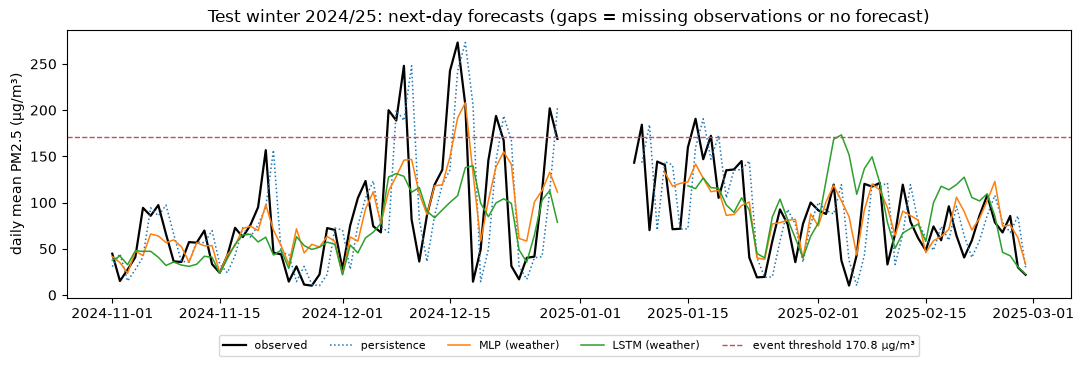

In [6]:
days = pd.date_range(table.index.min(), table.index.max(), freq="D")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(days, table["y"].reindex(days), color="k", lw=1.6, label="observed")
ax.plot(days, table["pm_lag0"].reindex(days), ls=":", lw=1.1, label="persistence")
ax.plot(days, table["pred_mlp (weather)"].reindex(days), lw=1.1, label="MLP (weather)")
ax.plot(days, table["pred_lstm (weather)"].reindex(days), lw=1.1, label="LSTM (weather)")
ax.axhline(THR, color="#C44E52", ls="--", lw=1, label=f"event threshold {THR:g} µg/m³")
ax.set_ylabel("daily mean PM2.5 (µg/m³)")
ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Test winter 2024/25: next-day forecasts (gaps = missing observations or no forecast)")
fig.tight_layout(); plt.show()

## 3 · Warning policy on the test winter
The frozen policy and the three single-threshold rules, all on the frozen policy's input forecast.

In [7]:
w = tr.warning_results(table, feat, cfg, policy)
show = ["alerts", "alerts_l1", "alerts_l2", "high_caught", "high_days", "caught_per_alert", "very_high_caught_l2",
        "very_high_days", "missed", "false_alarms_l1", "false_alarms_l2", "longest_alert_run", "longest_l2_run"]
display(pd.DataFrame(w["cards"]).T[show].style.format({"caught_per_alert": "{:.2f}"}))
h5 = w["h5"]
display(Markdown(f"**H5: {h5['verdict']}.** Unhealthy days caught per alert: policy {h5['policy_caught_per_alert']:.2f} vs "
                 f"{h5['matched_caught_per_alert']:.2f} for the single-threshold rule at the matched (validation) threshold "
                 f"{policy['matched_single_threshold']:.1f} µg/m³."))
display(Markdown("**Fatigue** (pre-declared secondary outcome; descriptive, no verdict)"))
display(pd.DataFrame(w["fatigue"]).T)

,alerts,alerts_l1,alerts_l2,high_caught,high_days,caught_per_alert,very_high_caught_l2,very_high_days,missed,false_alarms_l1,false_alarms_l2,longest_alert_run,longest_l2_run
policy,11.000000,8.000000,3.000000,4.000000,11.000000,0.36,1.000000,3.000000,7.000000,6.000000,1.000000,3.000000,2.000000
"single threshold, matched budget",11.000000,0.000000,11.000000,4.000000,11.000000,0.36,2.000000,3.000000,7.000000,0.000000,7.000000,3.000000,3.000000
single threshold,11.000000,0.000000,11.000000,4.000000,11.000000,0.36,2.000000,3.000000,7.000000,0.000000,7.000000,3.000000,3.000000
official line,98.000000,0.000000,98.000000,10.000000,11.000000,0.10,3.000000,3.000000,1.000000,0.000000,88.000000,44.000000,44.000000


**H5: NOT SUPPORTED.** Unhealthy days caught per alert: policy 0.36 vs 0.36 for the single-threshold rule at the matched (validation) threshold 170.0 µg/m³.

**Fatigue** (pre-declared secondary outcome; descriptive, no verdict)

,longest_warning_run,warnings,warnings 2024/25
policy,2,3,3
"single threshold, matched budget",3,11,11


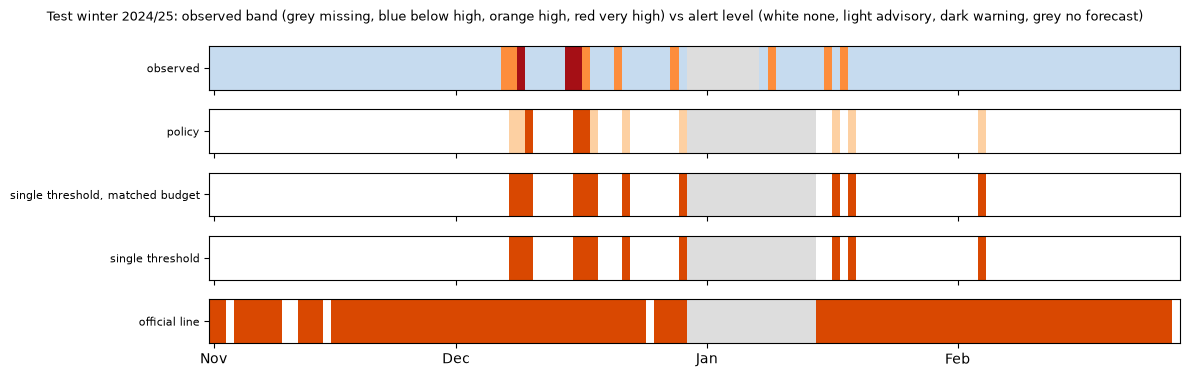

In [8]:
d = w["days"]
cal = pd.date_range(d.index.min(), d.index.max(), freq="D")
cal = cal[cal.month.isin(cfg["smog_months"])]
obs = d["y"].reindex(cal)
band = np.select([obs.isna(), obs > policy["very_high"], obs > cfg["warnings"]["high"]], [0, 3, 2], 1)
fc = d["forecast"].reindex(cal)
rules = ["policy", "single threshold, matched budget", "single threshold", "official line"]
rows = [band] + [np.where(fc.isna(), 0, d[f"level_{r}"].reindex(cal).fillna(0).to_numpy() + 1) for r in rules]
fig, axes = plt.subplots(len(rows), 1, figsize=(12, 3.8), sharex=True)
cm_obs = ListedColormap(["#DDDDDD", "#C6DBEF", "#FD8D3C", "#A50F15"])
cm_lev = ListedColormap(["#DDDDDD", "#FFFFFF", "#FDD0A2", "#D94801"])
for ax, r, cm, lab in zip(axes, rows, [cm_obs] + [cm_lev] * len(rules), ["observed"] + rules):
    ax.imshow(np.asarray(r)[None, :], aspect="auto", cmap=cm, vmin=0, vmax=3, interpolation="nearest")
    ax.set_yticks([0], [lab], fontsize=8)
ticks = [i for i, x in enumerate(cal) if x.day == 1]
axes[-1].set_xticks(ticks, [cal[i].strftime("%b") for i in ticks])
fig.suptitle("Test winter 2024/25: observed band (grey missing, blue below high, orange high, red very high) vs alert level "
             "(white none, light advisory, dark warning, grey no forecast)", fontsize=9)
fig.tight_layout(); plt.show()

## 4 · Network design on the test months (Feb–Mar 2026)
The subsets each method chose on validation (notebook 03) are scored on the test months; the models reconstructing dropped stations are refitted on train + validation, as in notebook 03's sealed cell. No selection is re-run; "random (median)" replays notebook 03's random draws.

method,exhaustive (optimum),genetic algorithm,greedy forward,highest mean,random (best of draws),random (median),spatial spread
k,,,,,,,
3,0.493,0.493,0.466,0.508,0.493,0.558,0.584
4,0.494,0.494,0.474,0.444,0.410,0.557,0.557
5,0.485,0.485,0.442,0.467,0.485,0.564,0.619
6,0.367,0.367,0.367,0.492,0.388,0.562,0.567
7,0.424,0.424,0.424,0.424,0.379,0.566,0.602
8,0.373,0.373,0.373,0.435,0.483,0.578,0.603
9,0.439,0.439,0.439,0.542,0.439,0.580,0.413
10,0.381,0.381,0.381,0.578,0.381,0.596,0.452
11,0.287,0.287,0.287,0.631,0.287,0.571,0.353


**H3: NOT SUPPORTED.** The GA subset beats random (median), highest-mean and spatial-spread and matches or beats greedy at 5 of 10 values of k ([6, 7, 8, 10, 11]).

**H4 (validation): SUPPORTED.** GA within 2% of the exhaustive optimum at 10 of 10 k. On the test months the GA subset's F minus the validation-optimal subset's F ranges +0.000 to +0.000.

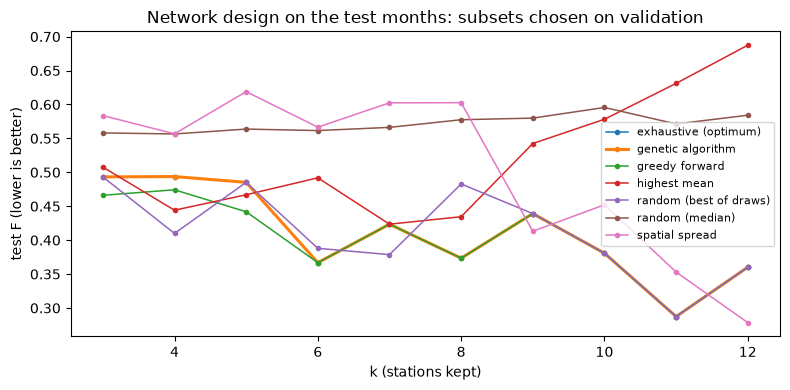

In [9]:
FCOL = "F_test"
net = tr.network_results(cfg, ROOT)
ft = net["table"].pivot(index="k", columns="method", values=FCOL)
display(ft.round(3))
h3, h4 = tr.verdict_h3(net["table"], FCOL), tr.verdict_h4(net["table"], FCOL)
display(Markdown(
    f"**H3: {h3['verdict']}.** The GA subset beats random (median), highest-mean and spatial-spread and matches or beats greedy at "
    f"{len(h3['k_won'])} of {h3['k_total']} values of k ({h3['k_won']}).\n\n"
    f"**H4 (validation): {h4['verdict']}.** GA within 2% of the exhaustive optimum at {h4['k_within_2pct']} of {h4['k_total']} k. "
    f"On the test months the GA subset's F minus the validation-optimal subset's F ranges "
    f"{min(h4['test_F_ga'][k] - h4['test_F_validation_optimum'][k] for k in h4['test_F_ga']):+.3f} to "
    f"{max(h4['test_F_ga'][k] - h4['test_F_validation_optimum'][k] for k in h4['test_F_ga']):+.3f}."))
fig, ax = plt.subplots(figsize=(8, 4))
for m in ft.columns:
    ax.plot(ft.index, ft[m], marker="o", ms=3, lw=2.2 if m == "genetic algorithm" else 1.1, label=m)
ax.set_xlabel("k (stations kept)"); ax.set_ylabel("test F (lower is better)"); ax.legend(fontsize=8)
ax.set_title("Network design on the test months: subsets chosen on validation")
fig.tight_layout(); plt.show()

## 5 · Summary of H1–H6

In [10]:
summary_rows = [
    {"hypothesis": "H1", "verdict": h1["verdict"], "key number": f"MLP skill {h1['mlp_skill_mae']:+.3f}; MAE diff {h1['mae_difference']:+.1f} "
                                                              f"({h1['interval'][0]:+.1f} to {h1['interval'][1]:+.1f})"},
    {"hypothesis": "H2", "verdict": h2["verdict"], "key number": f"MLP MAE with − without weather {h2['mlp_mae_difference_weather_minus_none']:+.2f}"},
    {"hypothesis": "H3", "verdict": h3["verdict"], "key number": f"GA wins at {len(h3['k_won'])} of {h3['k_total']} k"},
    {"hypothesis": "H4", "verdict": h4["verdict"], "key number": f"GA within 2% of optimum at {h4['k_within_2pct']} of {h4['k_total']} k (validation)"},
    {"hypothesis": "H5", "verdict": h5["verdict"], "key number": f"caught per alert {h5['policy_caught_per_alert']:.2f} vs {h5['matched_caught_per_alert']:.2f} (matched)"},
    {"hypothesis": "H6", "verdict": ban["verdict"], "key number": f"forest placebo {ban['placebo']['rf']['effect']:+.1%} (rule ±15%); "
                                                               f"pooled effect {ban['pooled']['rf']['effect']:+.1%} (notebook 07)"},
]
summary = pd.DataFrame(summary_rows).set_index("hypothesis")
with pd.option_context("display.max_colwidth", 120):
    display(summary)

,verdict,key number
hypothesis,,
H1,SUPPORTED,MLP skill +0.189; MAE diff -6.9 (-10.7 to -3.3)
H2,SUPPORTED,MLP MAE with − without weather -0.52
H3,NOT SUPPORTED,GA wins at 5 of 10 k
H4,SUPPORTED,GA within 2% of optimum at 10 of 10 k (validation)
H5,NOT SUPPORTED,caught per alert 0.36 vs 0.36 (matched)
H6,inconclusive (placebo outside ±15%),forest placebo +31.4% (rule ±15%); pooled effect -25.2% (notebook 07)


## 6 · Save
New files only; configs and earlier results are never written. The log was written in section 1.

In [11]:
net_out = net["table"].assign(stations=net["table"]["stations"].map(lambda s: ", ".join(s) if isinstance(s, list) else ""))
written = tr.save_outputs(ROOT, {
    "test_forecast.csv": table.reset_index(),
    "test_warning.csv": w["days"].reset_index(),
    "test_warning.json": {"policy": {k: policy[k] for k in ("input", "t1", "t2", "very_high", "matched_single_threshold")},
                          "cards": w["cards"], "h5": h5, "fatigue_descriptive": w["fatigue"]},
    "network_test.csv": net_out,
    "test_summary.json": {"log": log, "threshold": THR,
                          "verdicts": {"H1": h1, "H2": h2, "H3": h3, "H4": h4, "H5": h5,
                                       "H6": {"verdict": ban["verdict"], "source": "notebook 07"}},
                          "fatigue_descriptive": w["fatigue"],
                          "forecast_scores": scores[cols].to_dict(orient="index"),
                          "bootstrap": boot, "weather_ablation": ablation.to_dict(orient="index")},
})
for p in written:
    print("Saved", p)

Saved /Users/user/Desktop/neural/outputs/results/test_forecast.csv
Saved /Users/user/Desktop/neural/outputs/results/test_warning.csv
Saved /Users/user/Desktop/neural/outputs/results/test_warning.json
Saved /Users/user/Desktop/neural/outputs/results/network_test.csv
Saved /Users/user/Desktop/neural/outputs/results/test_summary.json
